# Practice 4 — Dự báo chuỗi thời gian đa biến

## Electricity Load + Weather

**Báo cáo trình bày** · Forecast phụ tải điện trước 1 giờ · So sánh VAR, XGBoost và LSTM

**Tóm tắt.** Bài thực hành xây dựng quy trình dự báo phụ tải điện theo giờ, dùng lịch sử phụ tải và các proxy thời tiết. Ba mô hình chính được so sánh trên cùng khoảng test theo walk-forward. Trên test, XGBoost có RMSE thấp nhất **445,95 MW**; tuy nhiên LSTM là mô hình được chọn theo validation nên thứ hạng test chỉ được báo cáo mô tả, không dùng để đổi cấu hình.

Notebook này trình bày theo thứ tự: bài toán → dữ liệu → khám phá → xử lý → đặc trưng → mô hình → backtesting → kết quả → trả lời câu hỏi. Các cell chỉ đọc artifact đã có trong repository; không tải dữ liệu, huấn luyện, tuning hay dựng lại test.


## Lưu ý quan trọng về dữ liệu so với đề PDF

PDF nêu **Electricity Load Diagrams Dataset (UCI)**. Dự án hiện tại dùng bộ **Hourly energy demand, generation and weather** cho Tây Ban Nha, nguồn được ghi trong data contract là Kaggle (upstream được khai báo là ENTSO-E và OpenWeatherMap). Đây là lựa chọn dataset đã được chốt trước đó trong quá trình triển khai, nhưng **không phải cùng dataset UCI** được gọi tên trong đề.

Vì vậy, kết quả bên dưới chứng minh quy trình và mô hình cho dữ liệu Tây Ban Nha hiện tại. Nếu giảng viên yêu cầu đúng dataset UCI, cần xác nhận dataset thay thế có được chấp nhận hay không; nếu không, phải chạy lại các bước data preparation, split, EDA, preprocessing, feature/model fitting, validation và test. Không thể chuyển metrics hiện tại sang dataset khác.


## 1. Mục tiêu và phát biểu bài toán

Mục tiêu là ước lượng phụ tải điện thực tế ở bước thời gian tiếp theo từ các quan sát đa biến đã có. Gọi vector dữ liệu tại giờ `t` là:

\[
X_t = [load_t, temperature_t, humidity_t, wind\_speed_t]
\]

Bài toán dự báo một bước:

\[
(X_{t-23}, \ldots, X_t) \longrightarrow load_{t+1}
\]

Phụ tải là biến mục tiêu và được đánh giá bằng MW. Ba thước đo chính là MAE, RMSE và MAPE. Hai baseline persistence và seasonal-24 được thêm làm mốc so sánh trước khi đánh giá các mô hình phức tạp hơn.


## 2. Dataset, đơn vị và phạm vi quan sát

Canonical data có **35.064 giờ liên tục**, từ 2014-12-31 23:00 UTC đến 2018-12-31 22:00 UTC. Các biến thời tiết là trung bình không trọng số của năm thành phố Madrid, Barcelona, Valencia, Seville và Bilbao. Do đó, chúng là proxy thời tiết khu vực, không phải phép đo thời tiết trực tiếp tại toàn bộ vùng phụ tải.

| Biến | Ý nghĩa | Đơn vị |
|---|---|---|
| `load` | Phụ tải điện thực tế | MW |
| `temp` | Nhiệt độ trung bình proxy | K |
| `humidity` | Độ ẩm proxy | % |
| `wind_speed` | Tốc độ gió proxy | m/s |
| `timestamp_utc` | Thời điểm quan sát | UTC |

Toàn bộ chuỗi được giữ theo UTC để ghép và dự báo. Giờ địa phương `Europe/Madrid` chỉ dùng cho phân tích theo giờ trong ngày và thứ trong tuần; hai quan sát cùng giờ địa phương do DST được giữ riêng.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'outputs').exists() and (ROOT.parent / 'outputs').exists():
    ROOT = ROOT.parent
metrics = pd.read_csv(ROOT / 'outputs/tables/test_metrics.csv').set_index('model')
predictions = pd.read_csv(ROOT / 'outputs/predictions/test_predictions.csv')
groups = pd.read_csv(ROOT / 'runs/20261120_system312_h02_02/artifacts/grouped_errors.csv')
split = json.loads((ROOT / 'datasets/processed/split_manifest.json').read_text(encoding='utf-8'))
scaler = json.loads((ROOT / 'runs/20261118_system312_d02_01/artifacts/scaler.json').read_text(encoding='utf-8'))
assert set(metrics.index) == {'persistence', 'seasonal24', 'VAR', 'XGB', 'LSTM'}
assert predictions.groupby('model').size().eq(5259).all()
assert len(groups) == 270
print('Loaded accepted H01/H02 outputs; no raw or canonical dataset was loaded.')


Loaded accepted H01/H02 outputs; no raw or canonical dataset was loaded.


### Kiểm tra trước khi phân tích

Các kiểm tra sau xác nhận cấu trúc đầu ra mà notebook sắp trình bày: đủ năm model, mỗi model có cùng số dự báo đã chấm; bảng nhóm phải là artifact của H02. Cell này không đọc CSV raw hoặc canonical.


In [2]:
split_rows = []
for name, info in split['splits'].items():
    split_rows.append({'split': name, 'rows': info['row_count'], 'share_%': 100 * info['row_count'] / split['total_rows'], 'start_utc': info['start_utc'], 'end_utc': info['end_utc']})
display(pd.DataFrame(split_rows).set_index('split').round({'share_%': 2}))
print('Test prediction rows by model:')
display(predictions.groupby('model').size().rename('scored_targets').to_frame())


,rows,share_%,start_utc,end_utc
split,,,,
train,24544,70.0,2014-12-31T23:00:00+00:00,2017-10-19T14:00:00+00:00
validation,5259,15.0,2017-10-19T15:00:00+00:00,2018-05-26T17:00:00+00:00
test,5261,15.0,2018-05-26T18:00:00+00:00,2018-12-31T22:00:00+00:00


Test prediction rows by model:


,scored_targets
model,
LSTM,5259
VAR,5259
XGB,5259
persistence,5259
seasonal24,5259


## 3. Chia dữ liệu theo thời gian

Dữ liệu được chia theo thứ tự thời gian, không shuffle. Số hàng canonical gần đúng tỷ lệ 70% train, 15% validation và 15% test:

- **Train:** 24.544 giờ, kết thúc 2017-10-19 14:00 UTC.
- **Validation:** 5.259 giờ, kết thúc 2018-05-26 17:00 UTC.
- **Test:** 5.261 giờ, bắt đầu 2018-05-26 18:00 UTC.

Scaler và trọng số model được fit/chọn từ train và validation theo từng quy trình đã khóa. Test chỉ được mở ở bước đánh giá cuối cùng. Context quá khứ sát biên split được giữ khi timestamp của nó không vượt qua forecast origin.


## 4. Data understanding và EDA trên train

EDA được thực hiện trên train để tránh nhìn trước test. Các câu hỏi chính là: dữ liệu có missing hoặc giá trị bất thường không; phụ tải biến thiên theo thời gian và lịch địa phương thế nào; thời tiết có tương quan tuyến tính hay hình thái phi tuyến với phụ tải; chuỗi có phụ thuộc theo các lag ngày/tuần không?


**Khoảng trống và độ dài các đoạn thiếu tải trong train.**

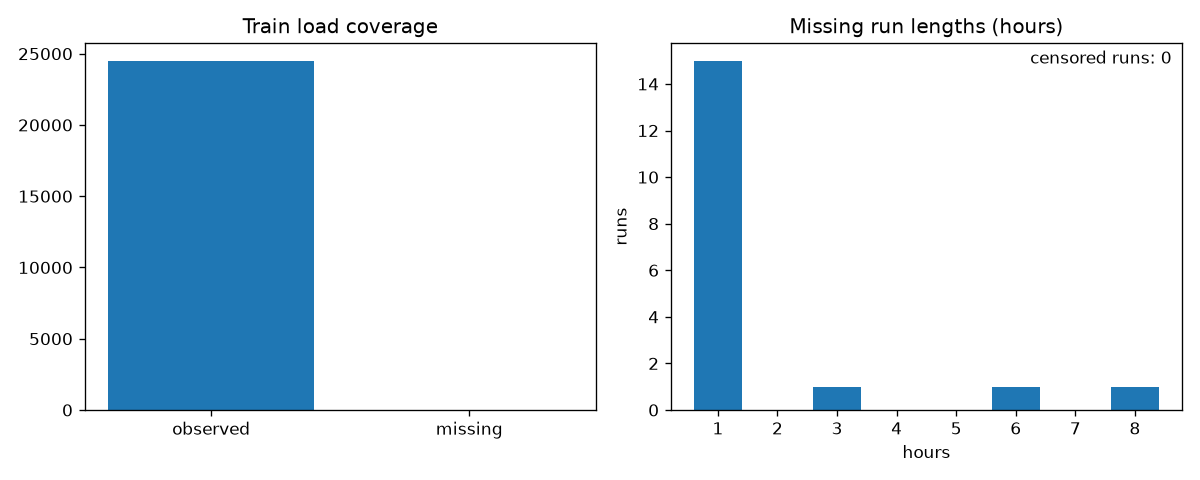

**Phân phối và các giá trị cực trị trong train; cờ cực trị không tự khẳng định dữ liệu sai.**

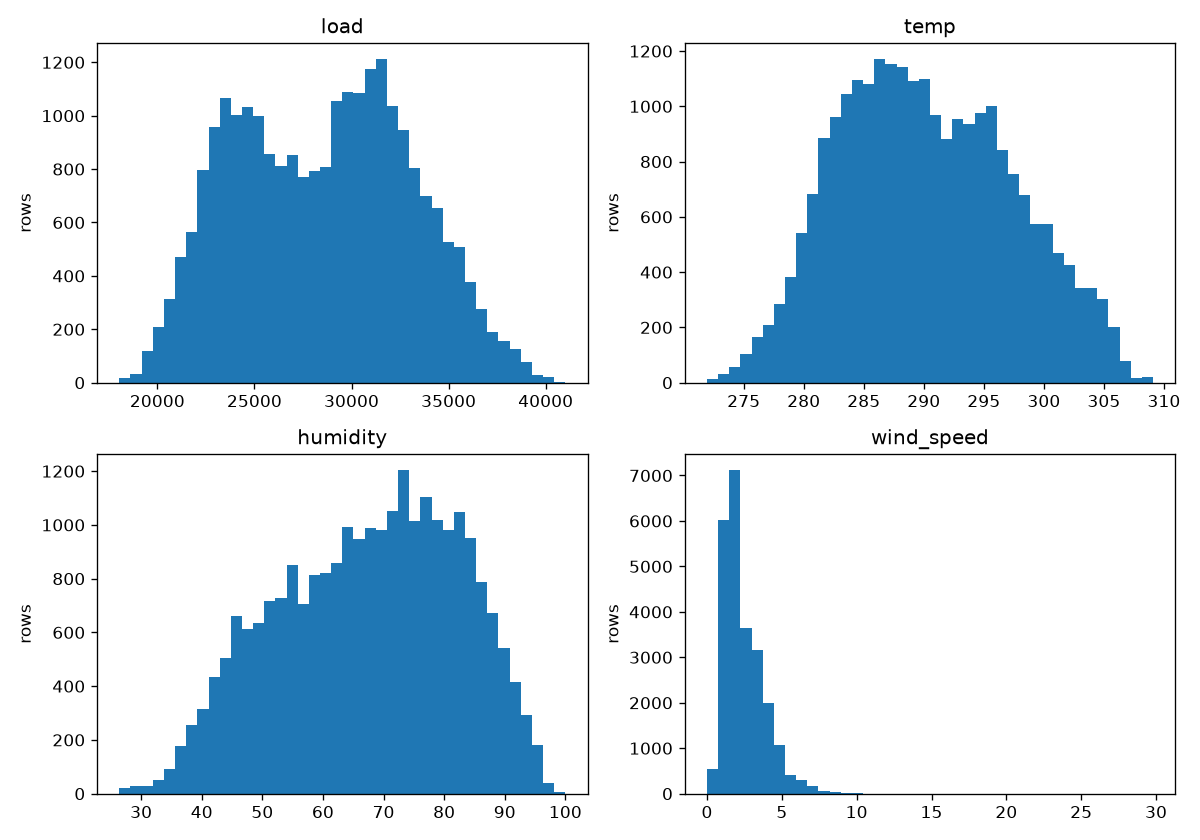

In [3]:
for filename, caption in [
    ('missing_gaps.png', 'Khoảng trống và độ dài các đoạn thiếu tải trong train.'),
    ('extremes.png', 'Phân phối và các giá trị cực trị trong train; cờ cực trị không tự khẳng định dữ liệu sai.')]:
    display(Markdown(f'**{caption}**'))
    display(Image(filename=str(ROOT / 'outputs/figures' / filename)))


### Diễn giải chất lượng dữ liệu

Trong train có **32 giá trị phụ tải thiếu trên 24.544 giờ** (0,130%). Có 18 đoạn thiếu: 15 đoạn dài một giờ, và các đoạn còn lại dài 3, 6, 8 giờ. Ba biến thời tiết không thiếu trong train. Kiểm tra miền cơ bản không phát hiện tải/gió âm, nhiệt độ Kelvin không dương hay độ ẩm ngoài 0–100%.

Các giá trị ngoài percentile train 0,5–99,5 được đánh dấu để xem xét, không tự động xóa hoặc cắt. Đây là phân biệt quan trọng: một giá trị cực trị có thể là đỉnh tải/thời tiết thật, không mặc định là lỗi sensor.


**Diễn biến phụ tải theo thời gian UTC trong train.**

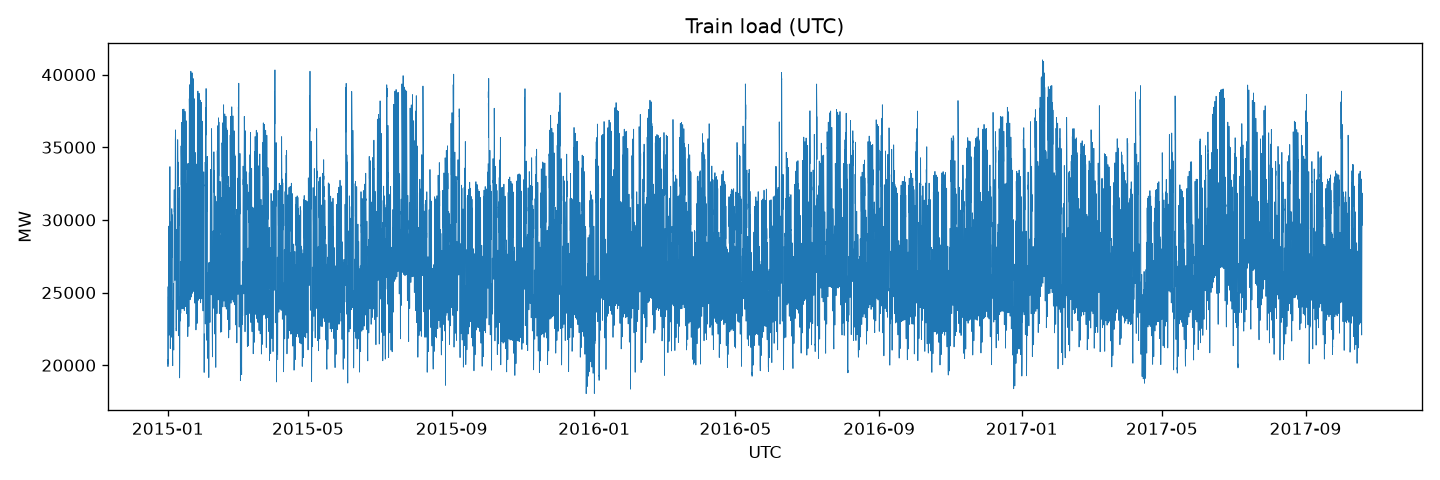

**Mẫu hình phụ tải theo giờ và thứ tại Europe/Madrid.**

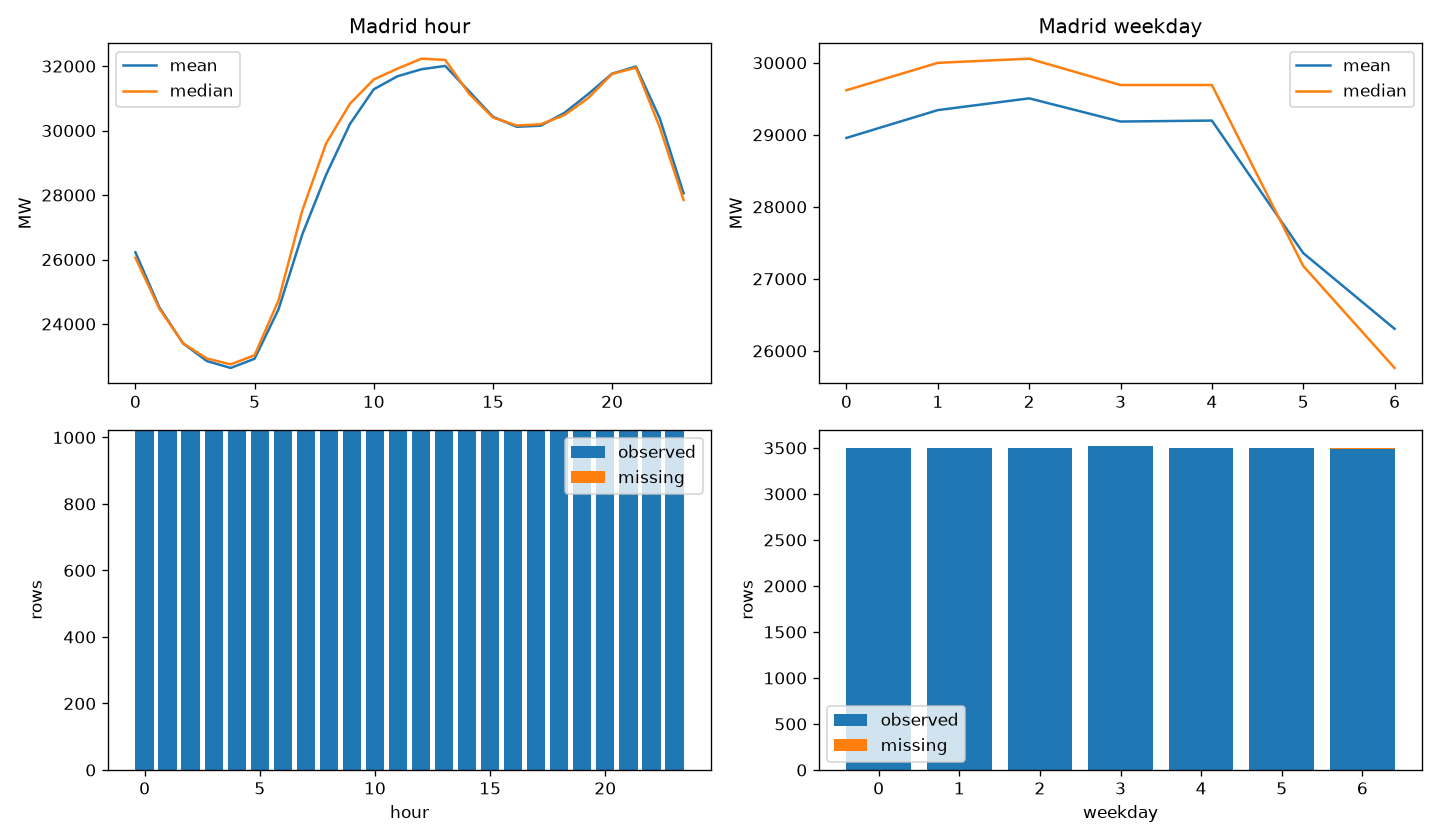

**Quan hệ tải–nhiệt độ và ma trận tương quan trên các cặp train quan sát được.**

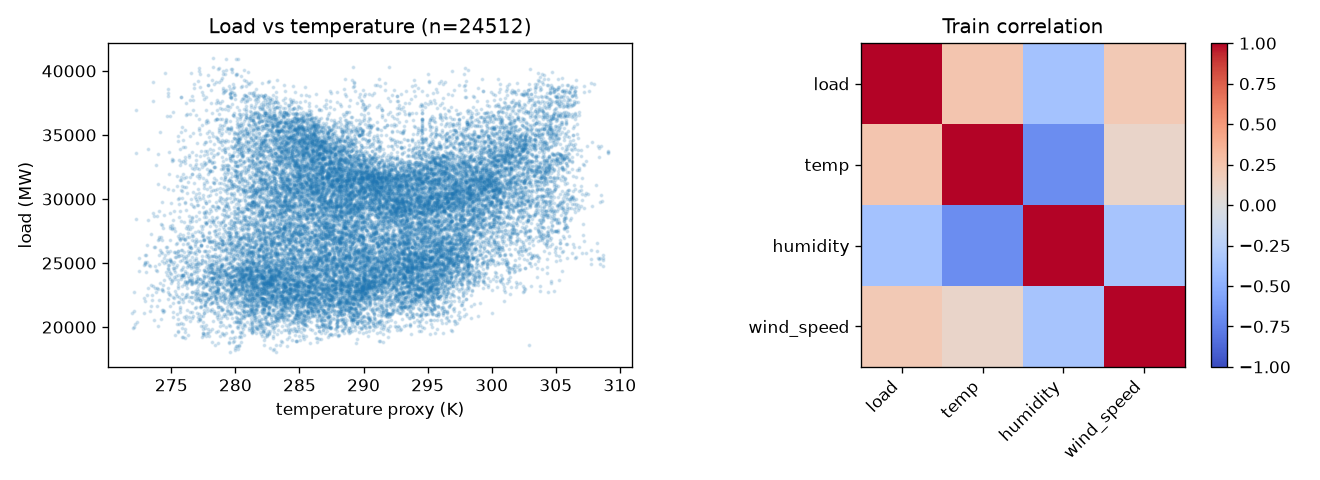

**ACF/PACF trên đoạn train quan sát liên tục dài nhất.**

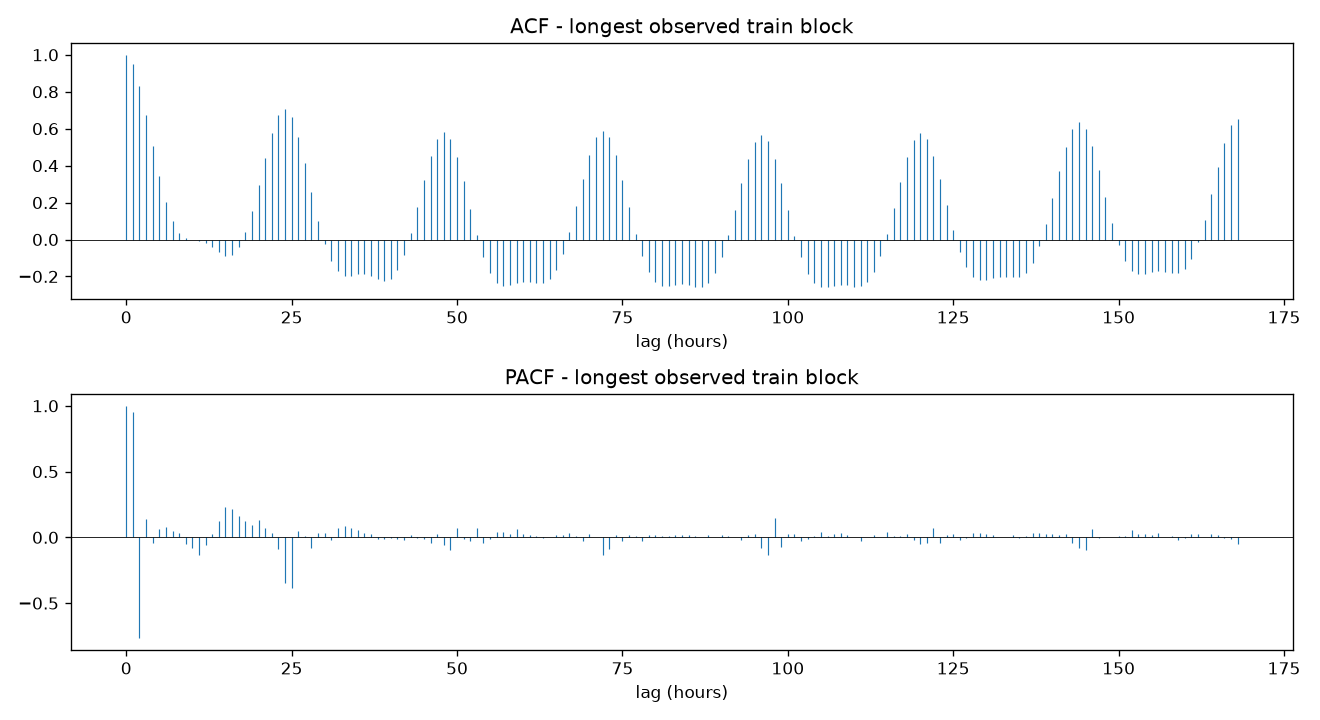

In [4]:
for filename, caption in [
    ('load_utc.png', 'Diễn biến phụ tải theo thời gian UTC trong train.'),
    ('local_profiles.png', 'Mẫu hình phụ tải theo giờ và thứ tại Europe/Madrid.'),
    ('relationships.png', 'Quan hệ tải–nhiệt độ và ma trận tương quan trên các cặp train quan sát được.'),
    ('acf_pacf.png', 'ACF/PACF trên đoạn train quan sát liên tục dài nhất.')]:
    display(Markdown(f'**{caption}**'))
    display(Image(filename=str(ROOT / 'outputs/figures' / filename)))


### Diễn giải cấu trúc chuỗi và thời tiết

Phụ tải có mẫu hình giờ trong ngày và ngày trong tuần rõ. Trung bình train khoảng **22.635 MW lúc 04:00** và **32.007 MW lúc 13:00** theo giờ Madrid; Chủ nhật khoảng 26.307 MW, thấp hơn Thứ Tư khoảng 29.506 MW.

Trên 24.512 cặp tải–thời tiết được quan sát trong train, Pearson correlation lần lượt là: nhiệt độ **0,236**, độ ẩm **−0,367**, gió **0,209**. Độ ẩm có tương quan tuyến tính lớn nhất theo trị tuyệt đối. Scatter tải–nhiệt độ có độ phân tán đáng kể; không thể từ đó kết luận quan hệ nhân quả hay một đường cong ổn định.

ACF tại lag 1, 24 và 168 xấp xỉ 0,952, 0,706 và 0,654. Tuy nhiên, ACF/PACF được tính trên đoạn liên tục 9.271 giờ; 15.241 giờ quan sát khác nằm ngoài đoạn này. Vì vậy đây là bằng chứng phụ thuộc thời gian hữu ích nhưng có giới hạn đại diện, không phải căn cứ duy nhất để chọn mô hình.


## 5. Preprocessing và kiểm soát leakage

Các biến được chuẩn hóa theo thống kê train bằng **StandardScaler**. Bộ scaler không được fit lại trên validation/test. Cột `load_input` dùng cho model được tách khỏi nhãn phụ tải thực tế để không làm thay đổi truth.

Với tải thiếu, quy tắc forecast-time là **causal LOCF-1**: chỉ carry giá trị quan sát gần nhất qua tối đa một giờ thiếu liên tiếp. Nếu thiếu dài hơn, context tiếp tục invalid cho đến khi có tải quan sát lại. Nhãn thiếu vẫn giữ missing và không được chấm bằng giá trị impute. Giá trị ngoài percentile được đánh dấu, không clip.


In [5]:
scale_table = pd.DataFrame({'feature': scaler['feature_order'], 'train_mean': scaler['mean'], 'train_std': scaler['std']})
display(scale_table.set_index('feature').round(4))
print('Scaler fit rows:', scaler['fit_count'])
print('LOCF maximum consecutive gap:', scaler['locf_max_gap'])


,train_mean,train_std
feature,,
load_input,28552.1097,4536.5032
temp,290.2630,7.2050
humidity,67.4750,14.8435
wind_speed,2.4491,1.3748


Scaler fit rows: 24530
LOCF maximum consecutive gap: 1


## 6. Feature engineering và căn chỉnh nhãn

Mỗi forecast dùng thông tin đã có đến hết giờ origin `t`, nhãn là phụ tải quan sát tại `t+1`.

| Mô hình | Dạng input |
|---|---|
| LSTM | Tensor `(24 giờ, 4 biến)`, theo thứ tự thời gian từ cũ đến mới |
| XGBoost | 96 giá trị lag đã scale (24 × 4) và 3 thống kê phụ tải |
| VAR | Vector mức tải/thời tiết 4 chiều trong một đoạn train liên tục |
| Baselines | Tải hiện tại (persistence) hoặc tải cùng giờ ngày trước (seasonal-24) |

XGBoost có thêm `mean6h`, `std24h` (population standard deviation, `ddof=0`) và `trend24h = load(t) − load(t−24)`. Các rolling/statistics chỉ dùng dữ liệu tại hoặc trước origin. Model không được nhận thời tiết của target hour.

Warm-up 25 hàng được dùng chung để duy trì trạng thái xử lý missing; input LSTM chính nó dùng 24 bước. Nhãn luôn là tải thô quan sát được tại `t+1`, tính điểm trên MW.


## 7. Mô hình và cách lựa chọn

### Baselines

- **Persistence:** dự báo tải ở giờ kế tiếp bằng tải gần nhất tại origin. Đây là mốc “không đổi so với hiện tại”.
- **Seasonal-24:** dùng tải tại cùng giờ của ngày trước. Baseline này kiểm tra xem chu kỳ 24 giờ đơn giản có đủ tốt không.

### VAR(24)

VAR dự báo đồng thời vector `[load, temperature, humidity, wind_speed]`, nhưng chỉ thành phần tải được đánh giá. ADF/KPSS được dùng để chẩn đoán tính dừng; quyết định đã khóa là `d=[0,0,0,0]`. Lag BIC chọn 24. Do cần đoạn đầy đủ, VAR được fit trên block liên tục 9.271 giờ và bỏ khỏi fit 15.241 giờ train quan sát khác; đây là hạn chế mẫu đáng kể.

### XGBoost

XGBoost học ánh xạ từ các lag và rolling features sang tải giờ kế tiếp. Grid thử depth 3/5/7 và số cây có early stopping validation. Model khóa là `XGB_full`, depth 7, 931 cây. Weather ablation `XGB_load_only` được dùng ở validation để xem tập feature thời tiết có cải thiện dự báo hay không.

### LSTM

Kiến trúc theo đề: `LSTM(64) → LSTM(32) → Dense(1)`, input 24 × 4, loss MSE, optimizer Adam. Training theo batch tuần tự, không shuffle; early stopping theo validation và khôi phục trọng số epoch tốt nhất. Hai learning rate được thử trong ngân sách khóa; mô hình được chọn là `lstm_lr_001`, best epoch 47, stop epoch 50, 30.113 trainable parameters.


## 8. Walk-forward backtesting và metric

Ở từng origin theo thứ tự thời gian, controller phát dự báo trước, sau đó mới đọc/reveal tải quan sát của giờ kế tiếp. Nếu target thiếu thì hàng đó không được chấm, nhưng vẫn áp dụng quy tắc cập nhật trạng thái đã định. Không model nào được fit lại hoặc tuning trong test; cả năm model dùng cùng key và truth.

Định nghĩa trên các cặp được chấm, với `eᵢ = yᵢ − ŷᵢ`:

- **MAE** = trung bình `|eᵢ|`, biểu diễn sai số tuyệt đối điển hình.
- **RMSE** = căn trung bình `eᵢ²`, phạt mạnh hơn các sai số lớn.
- **MAPE** = trung bình `|eᵢ / yᵢ| × 100%` chỉ trên `yᵢ ≠ 0`; không thêm epsilon.

Test gồm 5.261 candidate targets; 2 thiếu truth, 0 invalid context, còn **5.259** điểm chấm/model. Không có truth bằng zero bị loại khỏi MAPE.


In [6]:
display(metrics[['mae_mw', 'rmse_mw', 'mape_percent']].sort_values('rmse_mw').rename(columns={'mae_mw':'MAE (MW)','rmse_mw':'RMSE (MW)','mape_percent':'MAPE (%)'}).round(3))


,MAE (MW),RMSE (MW),MAPE (%)
model,,,
XGB,283.674,445.948,0.989
LSTM,301.805,458.507,1.055
VAR,477.260,681.532,1.686
persistence,1045.959,1383.862,3.688
seasonal24,2531.017,3618.578,8.758


### Dự báo và phân bố sai số trên test

Đồ thị dưới đây cho thấy tải thực tế theo UTC và residual `observed − forecast` của từng model. Biểu đồ residual distribution ẩn các điểm ngoại lai để dễ đọc nhưng các điểm đó vẫn được giữ trong metrics. Profile cuối biểu diễn MAE theo giờ đích địa phương Madrid; cả 24 giờ đều được giữ.


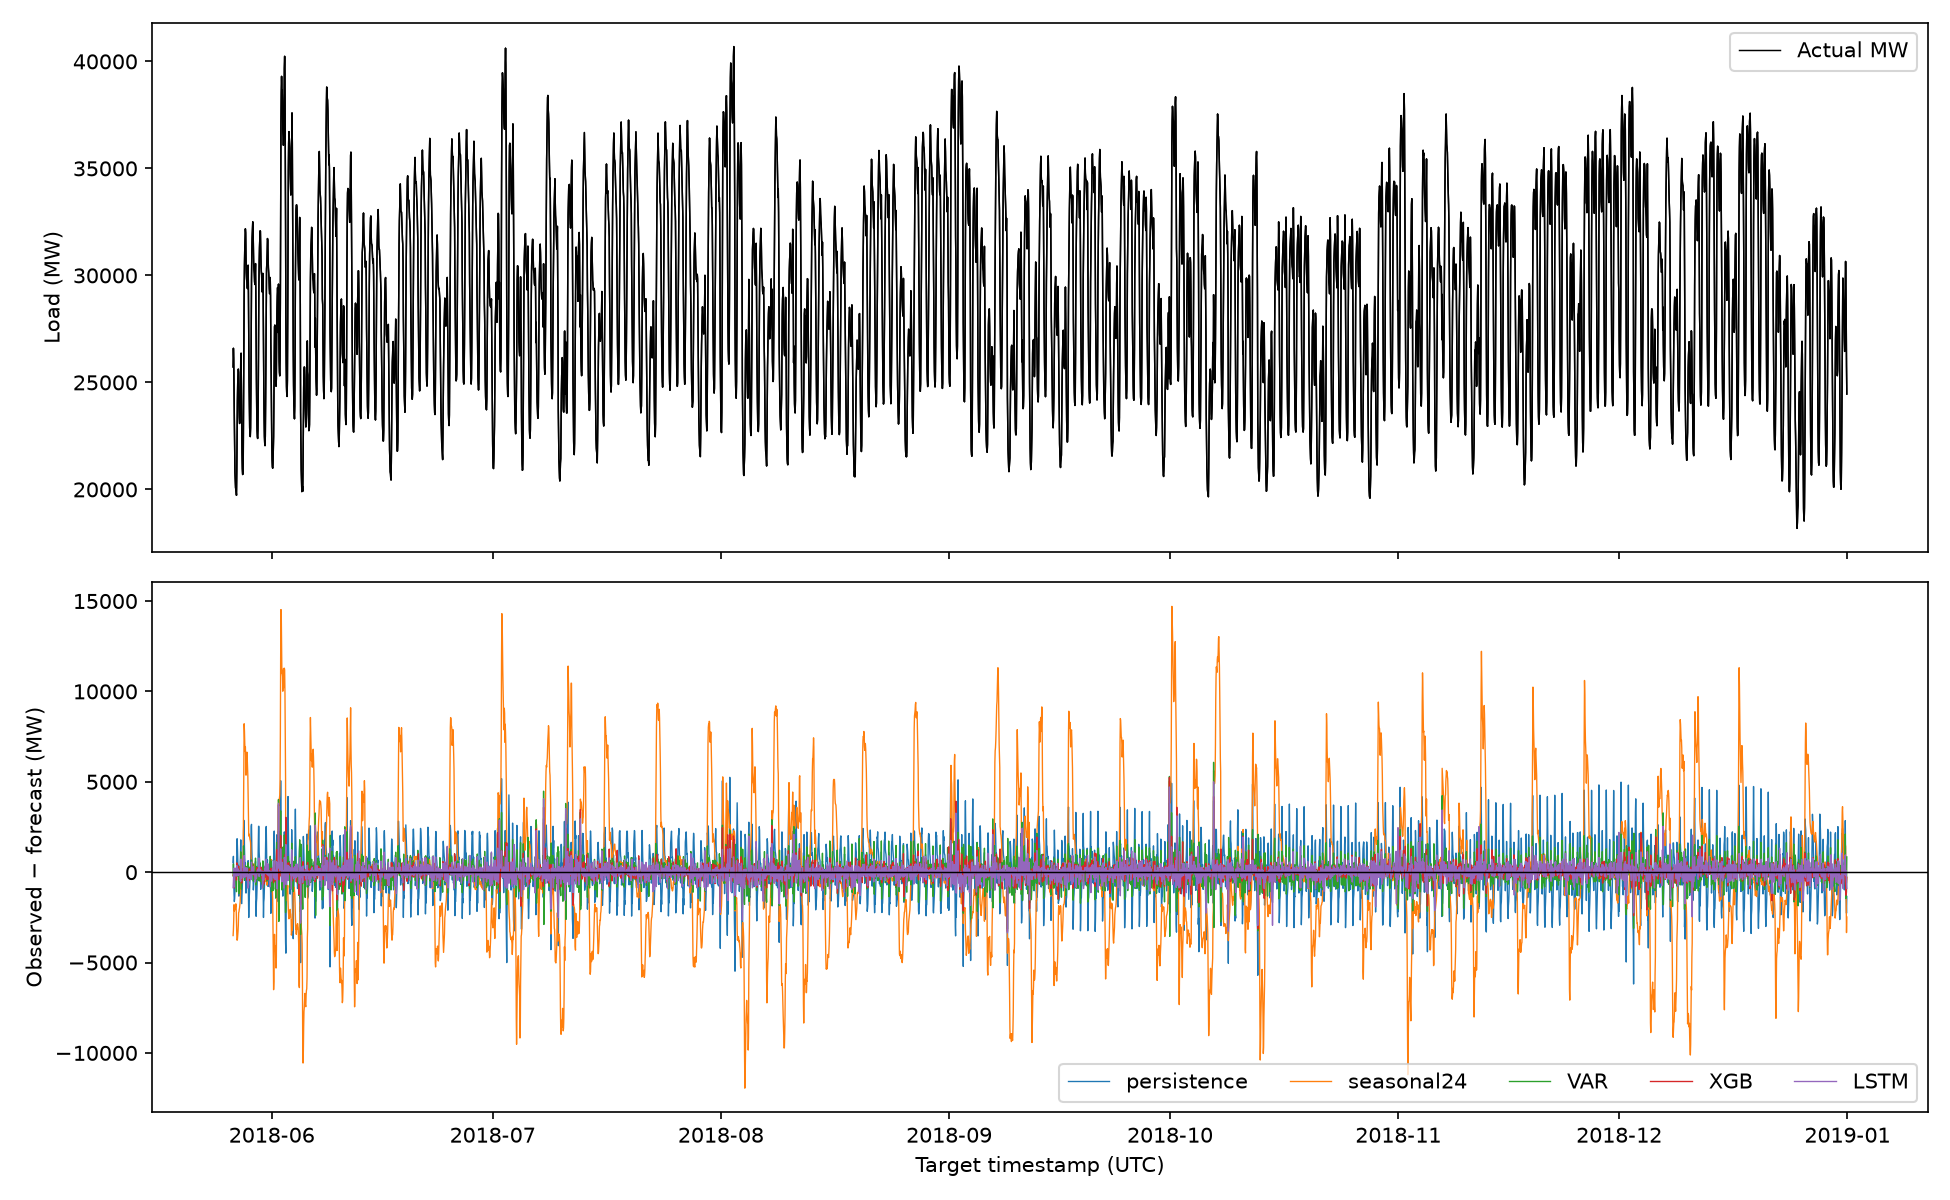

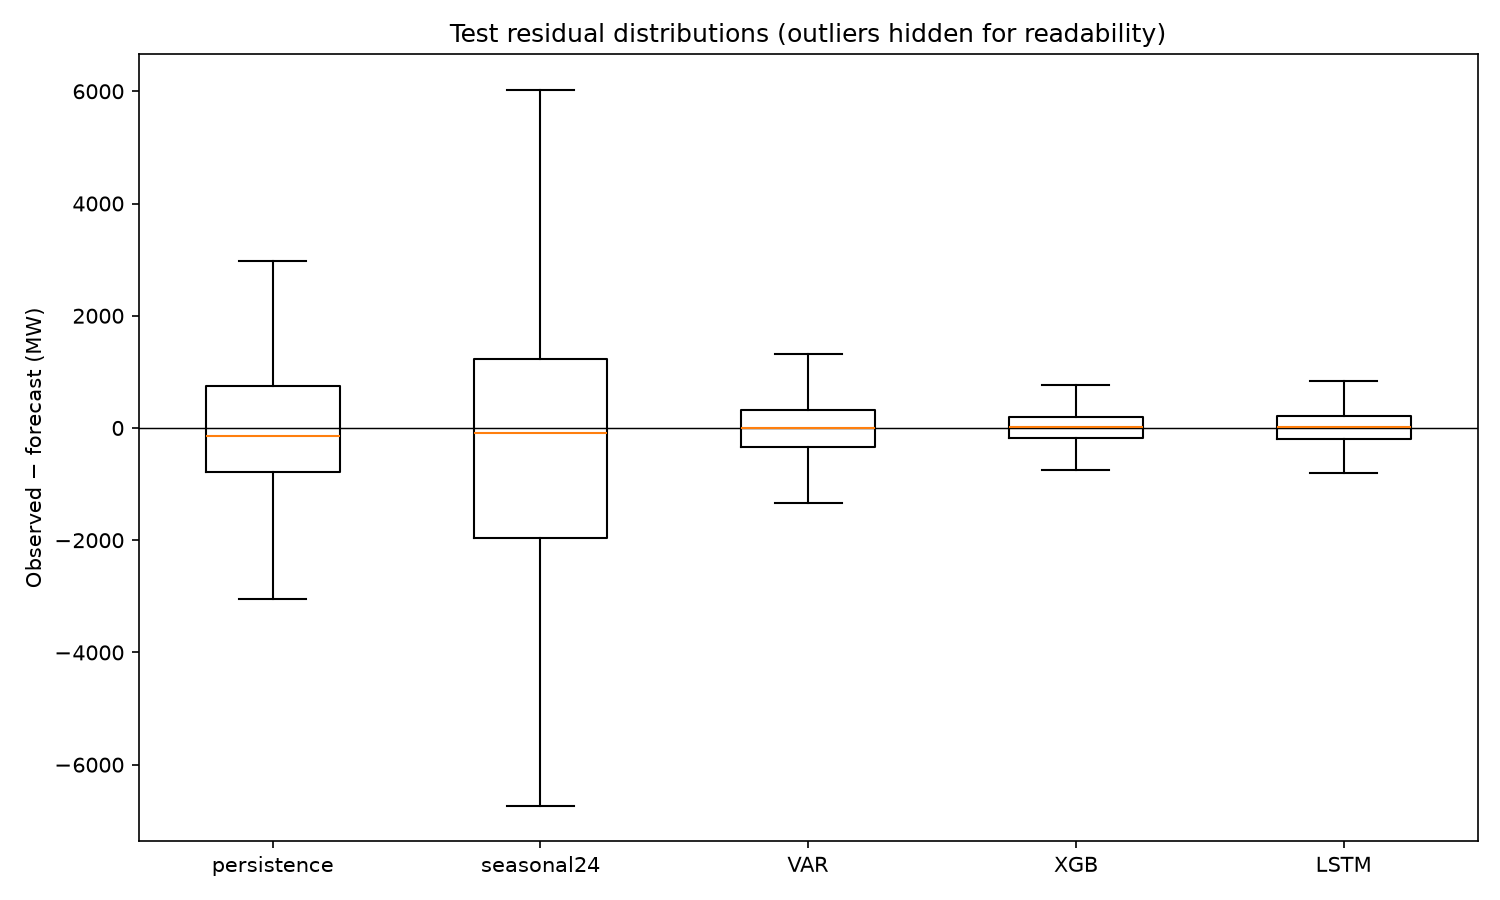

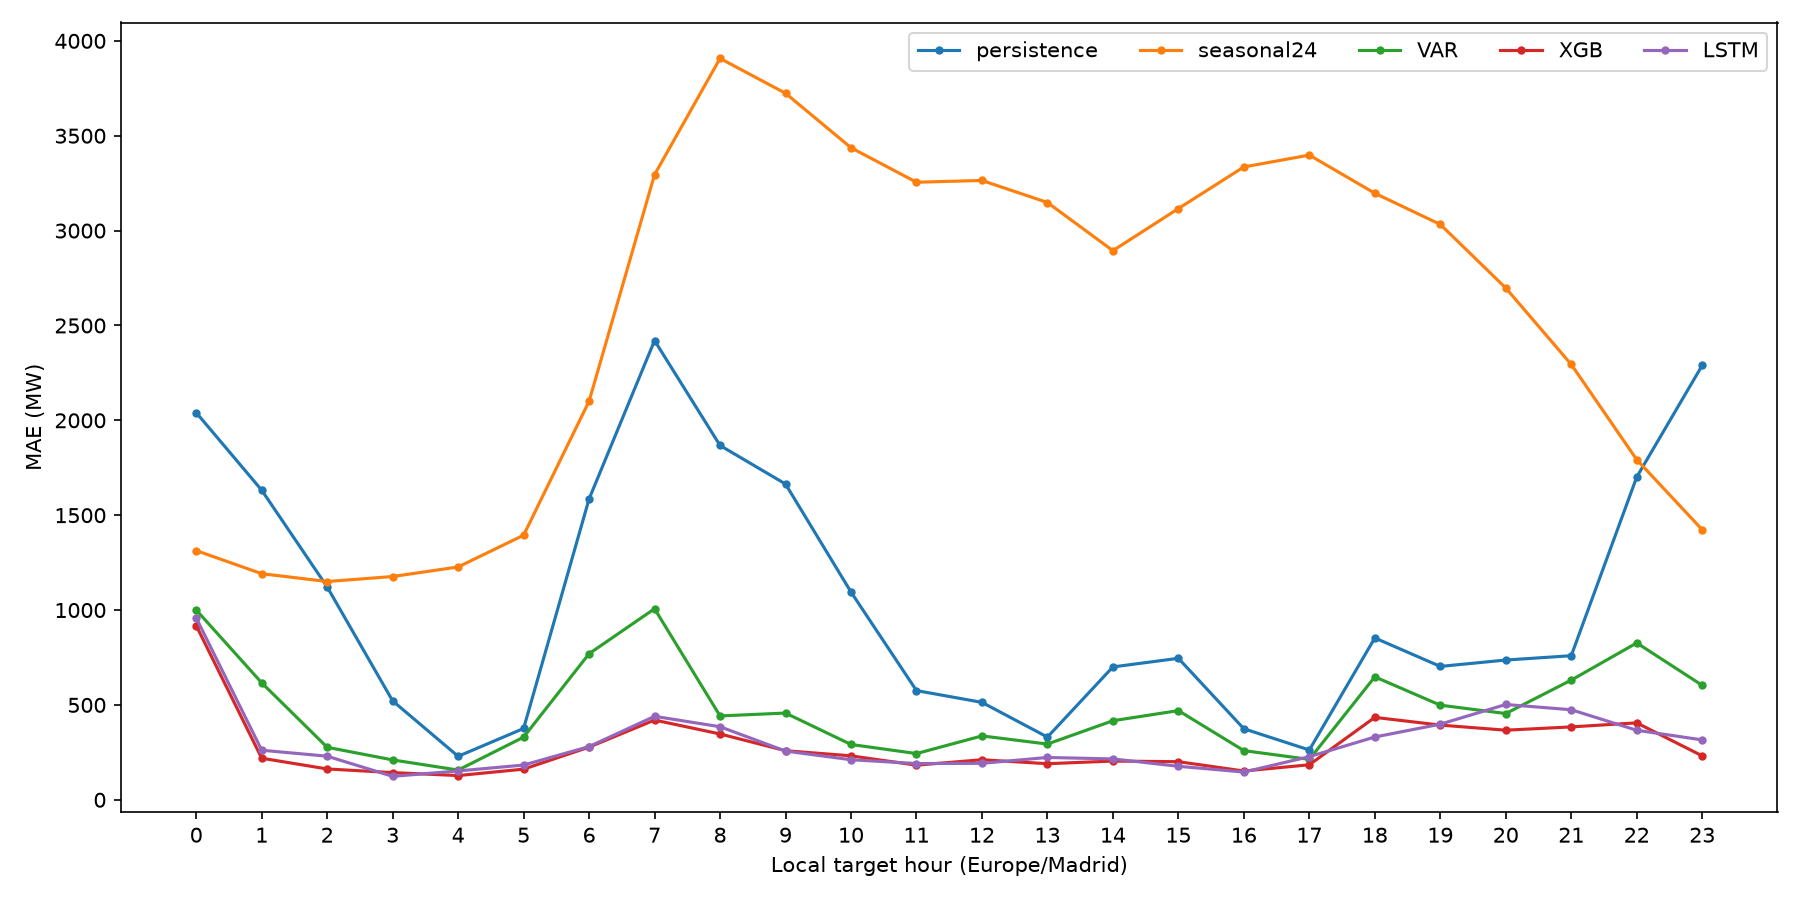

In [7]:
for filename in ['actual_vs_predicted.png', 'residual_distributions.png', 'grouped_error_profiles.png']:
    display(Image(filename=str(ROOT / 'outputs/figures' / filename)))


## 9. Thảo luận — trả lời sáu câu hỏi

### Câu 1. Biến thời tiết nào liên hệ mạnh nhất với phụ tải?

Cần tách hai ý nghĩa của “mạnh nhất”. Trong tương quan Pearson tuyến tính trên train, **độ ẩm** mạnh nhất theo trị tuyệt đối (`r = −0,367`), so với nhiệt độ (`0,236`) và gió (`0,209`). Trong feature gain của XGBoost, **nhiệt độ** có tổng gain lớn nhất trong các biến thời tiết (22,64 triệu; độ ẩm 16,03 triệu; gió 12,08 triệu). Hai thước đo không trả lời cùng một câu hỏi: Pearson đo liên hệ tuyến tính đơn biến; gain đo mức sử dụng split có điều kiện trong một model đã fit.

Ablation validation không chứng minh lợi ích gia tăng của weather trong thí nghiệm này: XGB_full RMSE **508,94 MW**, còn XGB_load_only **496,16 MW**. Do predictors có tương quan và feature gain không phải thí nghiệm nhân quả, không thể kết luận thời tiết “gây ra” thay đổi phụ tải.


### Câu 2. Khi nào VAR sai số lớn?

VAR có test RMSE **681,53 MW**, kém XGBoost và LSTM nhưng tốt hơn hai baseline. Phân nhóm H02 cho thấy RMSE cao nhất của VAR theo **giờ địa phương 00:00** là khoảng **1.467,98 MW (n=219)**, tiếp đến **07:00** khoảng **1.206,94 MW (n=219)**. Nhóm humidity vượt upper train bound có RMSE **997,00 MW (n=37)**; nhóm load thấp hơn lower train bound có RMSE **865,94 MW (n=12)**.

Hai nhóm tail thời tiết/tải có mẫu nhỏ, vì vậy các trị số này không ổn định như nhóm giờ trong ngày và không chứng minh nguyên nhân thất bại. Kết quả whiteness test của VAR cũng bác bỏ residual white noise ở mức 5%, cho thấy vẫn còn cấu trúc phụ thuộc chưa được mô hình giải thích. Đây là mô tả vùng sai số lớn, không phải kết luận nhân quả.


### Câu 3. XGBoost học gì từ thời tiết?

XGB_full có thể dùng nhiệt độ/độ ẩm/gió cùng lag tải và thống kê rolling. Tuy nhiên, gain tổng của tải (khoảng **1.557 tỷ**) lớn hơn nhiều so với tổng gain từng nhóm thời tiết; lag tải hiện tại `lag00_load` một mình đạt khoảng 1.131 tỷ. Điều này cho thấy model chủ yếu khai thác lịch sử phụ tải trong bộ feature đã thiết kế.

Validation ablation cho full model RMSE cao hơn load-only khoảng **12,77 MW**. Vì vậy bài này chưa cho thấy thêm weather đã cải thiện dự báo. Gain vẫn hữu ích để mô tả split behavior, nhưng bị ảnh hưởng bởi biến tương quan và không nên gọi là “ảnh hưởng nhân quả”.


### Câu 4. LSTM học chu kỳ ngày/tuần nào?

Residual autocorrelation của LSTM mạnh hơn ở lag ngày so với lag tuần. Validation: lag 24 giờ `r=0,2416` (5.231 cặp), lag 168 giờ `r=0,0958` (5.087 cặp). Test: lag 24 `r=0,2449` (5.235 cặp), lag 168 `r=0,1301` (5.091 cặp). Các MAE theo giờ/weekday cung cấp góc nhìn bổ sung.

Diễn giải cần thận trọng: residual autocorrelation còn lại không phải bằng chứng trực tiếp rằng hidden state “đã học” chu kỳ; input LSTM chỉ dài 24 giờ, không chứa trực tiếp lag 168. Kết luận hợp lý là có bằng chứng phụ thuộc ngày rõ hơn tuần trong residual, còn cấu trúc tuần chưa thuyết phục.


### Câu 5. LSTM có overfitting không?

Có **dấu hiệu overfit ở cuối training**. Best validation epoch là 47, training dừng ở epoch 50. Từ epoch 47 đến 50, validation loss tăng từ **0,012380** lên **0,013902**, trong khi training loss quanh **0,0091**. EarlyStopping khôi phục best weights ở epoch 47, nên việc dùng checkpoint đó là phù hợp với validation curve.

Điều này cho thấy áp lực overfit cuối quá trình, không khẳng định model thất bại trên mọi dữ liệu mới. Validation vừa được dùng để early stopping vừa dùng để lựa chọn trial, nên metric validation có thể lạc quan.


### Câu 6. Khác biệt giữa Machine Learning và Deep Learning ở bài này?

**XGBoost (ML)** nhận vector feature phẳng gồm lags/statistics, có thể xem gain để hiểu model sử dụng nhóm feature nào, training khá nhanh. **LSTM (DL)** nhận tensor tuần tự 24 × 4 và học biểu diễn qua recurrent layers; số tham số nhiều hơn và khó diễn giải trực tiếp hơn. Trong replay, G01 chạy 18 trial với 46,5 giây fit tổng; G02 chạy 2 trial với 425,1 giây fit tổng trên CPU.

Ở validation, LSTM được chọn trong năm ứng viên và có RMSE 504,75 MW, hơi tốt hơn XGB_full 508,94 MW. Trên test, XGBoost xếp trước LSTM (445,95 so với 458,51 MW RMSE; MAE 283,67 so với 301,80 MW). Đây là khác biệt thứ hạng giữa hai giai đoạn. Test không được dùng để đổi model lock; sự khác nhau cũng có thể phản ánh tính riêng của một test window.


## 10. Kết luận

Trên test window duy nhất đã mở, XGBoost đạt sai số thấp nhất theo cả ba metric chính: **MAE 283,67 MW; RMSE 445,95 MW; MAPE 0,9888%**. LSTM đứng thứ hai và khá sát: **MAE 301,80 MW; RMSE 458,51 MW; MAPE 1,0551%**. Validation trước đó chọn LSTM; vì thế kết quả test được dùng để báo cáo tổng quát hóa, không để chọn lại cấu hình.

Các baseline cho thấy bối cảnh khó: seasonal-24 có RMSE 3.618,58 MW, persistence 1.383,86 MW. VAR giảm đáng kể so với baseline nhưng vẫn kém hai model ML/DL trong test. Các kết quả này chỉ áp dụng cho dataset, split, availability assumption và test interval đang phân tích.


## 11. Giới hạn và cách trình bày trung thực

1. **Khác dataset trong PDF:** dự án dùng dataset Tây Ban Nha Kaggle thay cho Electricity Load Diagrams UCI. Đây là điểm cần xác nhận với giảng viên trước khi nộp nếu nguồn UCI là bắt buộc.
2. **Test chỉ là một đoạn:** từ cuối tháng 5 đến hết tháng 12 năm 2018, không bao phủ trọn một năm.
3. **Weather proxy:** trung bình không trọng số của năm thành phố có thể không đại diện chính xác cho địa điểm phụ tải.
4. **Availability:** walk-forward giả định tải thực tế của giờ vừa kết thúc sẵn sàng ngay cho bước dự báo kế tiếp.
5. **VAR sample:** mô hình dùng block train liên tục 9.271 giờ, loại khỏi fit 15.241 giờ train quan sát khác.
6. **Nhóm tail nhỏ:** kết quả ở một số nhóm extreme tải/thời tiết có ít quan sát, cần tránh diễn giải quá mức.
7. **Không phải causal study:** tương quan, feature gain và phân nhóm lỗi không chứng minh thời tiết gây ra biến động tải.

Mục traffic forecasting với METR-LA/PEMS-BAY nằm trong phần nâng cao riêng của đề và không thuộc kết quả cốt lõi được trình bày ở đây.


## 12. Tái lập và provenance

Notebook dùng kernel **Python 3.12 (Practice 4)**. Chạy từ thư mục `total_practice/Practice_4` hoặc `notebooks`; đường dẫn gốc được tìm từ vị trí hiện tại. Tất cả cell chỉ đọc file cục bộ: metrics/predictions H01, grouped errors/figures H02 và các findings/audits đã lưu. Không cần Internet và không đọc raw/canonical CSV trong notebook.

Artifact chi tiết:

- H01 prediction/metric manifest: `runs/20261120_system312_h01_03/`.
- H02 group table/figures/report: `runs/20261120_system312_h02_02/artifacts/`.
- Train-only EDA: `docs/results/eda_findings.md`.
- Preprocessing và scaler: `docs/results/preprocessing_audit.md` và `runs/20261118_system312_d02_01/artifacts/scaler.json`.
- VAR, XGBoost, LSTM: `docs/results/var_results.md`, `xgboost_findings.md`, `lstm_findings.md`.
- Mô tả đánh giá đầy đủ: `docs/results/model_comparison.md`.
